In [5]:
import numpy as np 
import pandas as pd 

In [6]:
df=pd.read_csv('spam.csv', encoding='latin-1')

In [7]:
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
4523,ham,I've sent Ì_ my part..,NaN,NaN,NaN
773,ham,I wil be there with in &lt;#&gt; minutes. Go...,NaN,NaN,NaN
2178,ham,"I don,t think so. You don't need to be going o...",NaN,NaN,NaN
2517,ham,"Sorry, I'll call later",NaN,NaN,NaN
4129,ham,And by when you're done I mean now,NaN,NaN,NaN


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 677.1 KB


In [9]:
df.shape

(5572, 5)

In [10]:
df=df.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'])

In [11]:
df=df.rename(columns={'v1':'target','v2':'text'})

In [12]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()
df['target'] = le.fit_transform(df['target'])

In [13]:
df.duplicated().sum()

np.int64(403)

In [14]:
df.drop_duplicates(keep='first', inplace=True)

In [15]:
df.duplicated().sum()

np.int64(0)

In [16]:
df.shape

(5169, 2)

In [17]:
df['target'].value_counts()

target
0    4516
1     653
Name: count, dtype: int64

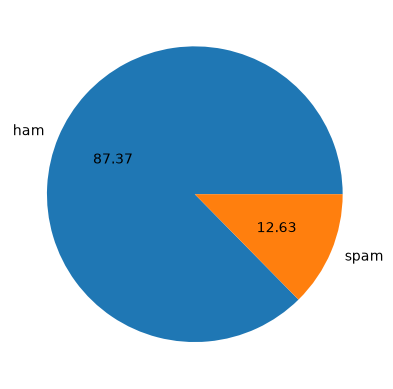

In [18]:
import matplotlib.pyplot as plt
plt.pie(df['target'].value_counts(), labels=['ham','spam'], autopct="%0.2f")

<Axes: xlabel='target', ylabel='count'>

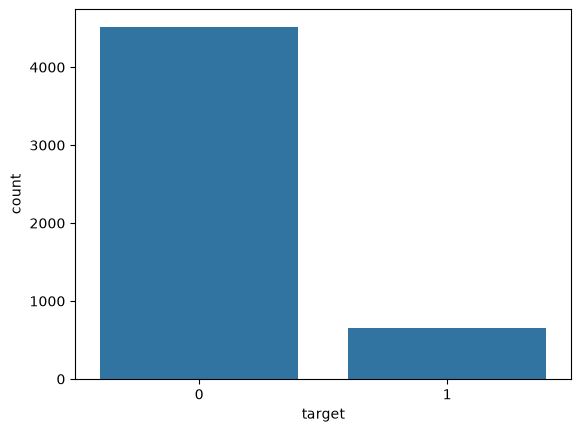

In [19]:
import seaborn as sns
sns.countplot(x='target', data=df)


In [20]:
import nltk

In [21]:
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Arpan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Arpan\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Arpan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [22]:
df['num_char']=df['text'].apply(len)

In [23]:
df.head(5)

,target,text,num_char
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [24]:
df['num_words']=df['text'].apply(lambda x:len(nltk.word_tokenize(x)))

In [25]:
df.head(5)

,target,text,num_char,num_words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [26]:
df['num_sentences']=df['text'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [27]:
df.head(5)

,target,text,num_char,num_words,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [28]:
df[df['target']==0][['num_char','num_words','num_sentences']].describe()

,num_char,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [29]:
df[df['target']==1][['num_char','num_words','num_sentences']].describe()

,num_char,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


In [30]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
target,5169.0,0.126330,0.332253,0.0,0.0,0.0,0.0,1.0
num_char,5169.0,78.977945,58.236293,2.0,36.0,60.0,117.0,910.0
num_words,5169.0,18.455794,13.324758,1.0,9.0,15.0,26.0,220.0
num_sentences,5169.0,1.965564,1.448541,1.0,1.0,1.0,2.0,38.0


<Axes: xlabel='num_char', ylabel='Count'>

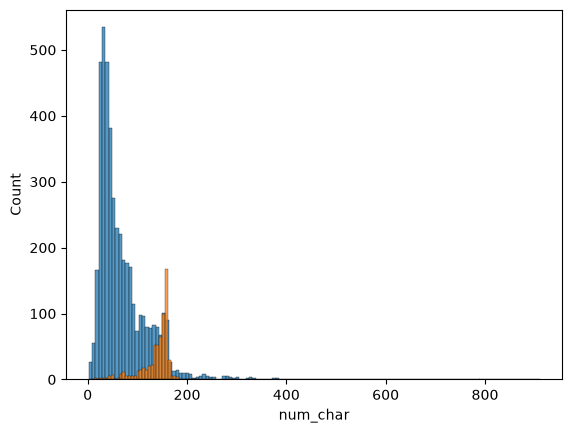

In [31]:
sns.histplot(df[df['target']==0]['num_char'])
sns.histplot(df[df['target']==1]['num_char']) 

<Axes: xlabel='num_words', ylabel='Count'>

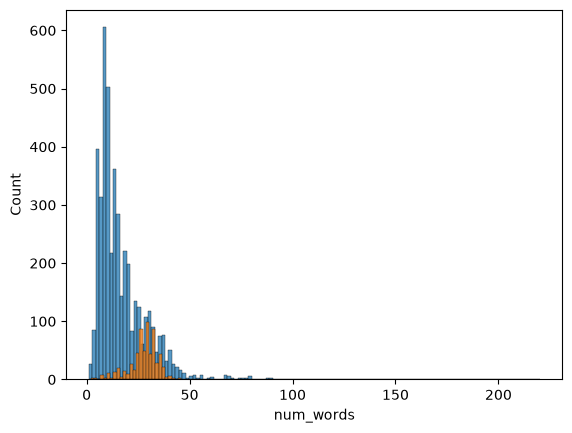

In [32]:
sns.histplot(df[df['target']==0]['num_words'])
sns.histplot(df[df['target']==1]['num_words']) 

<Axes: xlabel='num_sentences', ylabel='Count'>

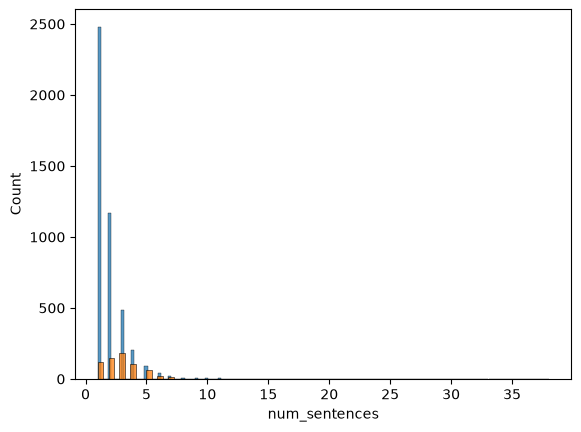

In [33]:
sns.histplot(df[df['target']==0]['num_sentences'])
sns.histplot(df[df['target']==1]['num_sentences']) 

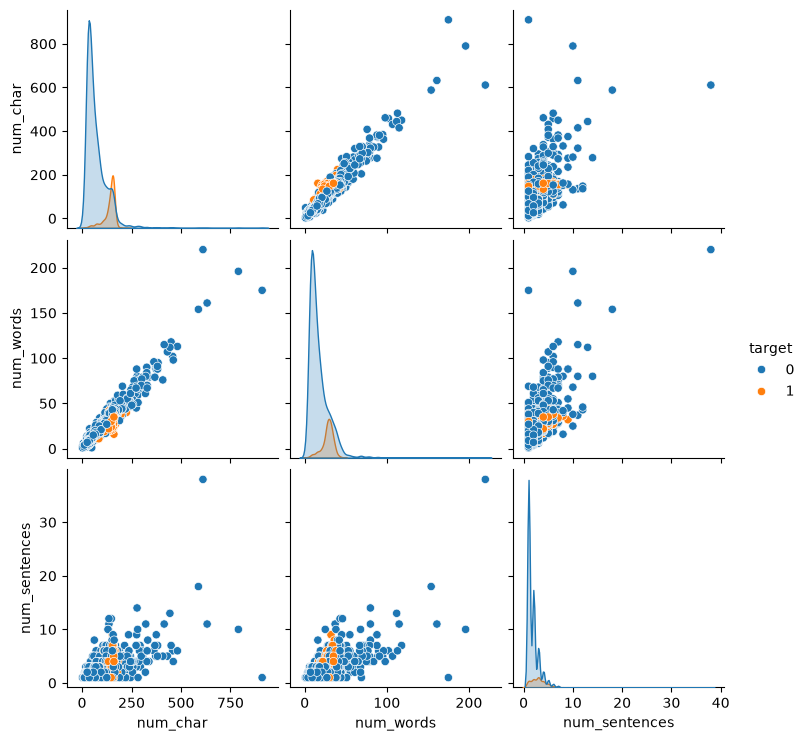

In [34]:
sns.pairplot(df, hue='target')

<Axes: >

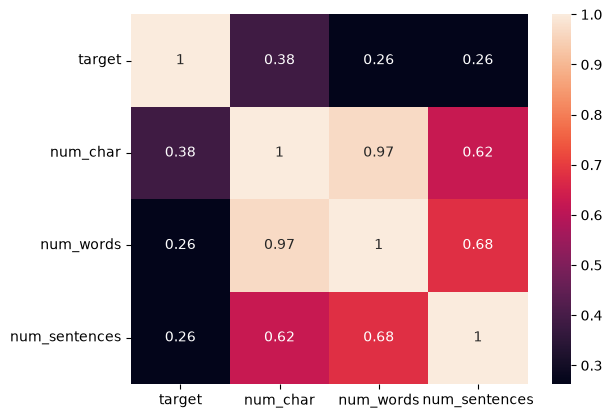

In [35]:
sns.heatmap(df.corr(numeric_only=True), annot=True)

In [36]:
import string 
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [37]:
from nltk.stem import PorterStemmer
ps = PorterStemmer()

from nltk.corpus import stopwords
nltk.download('stopwords')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Arpan\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [38]:
def transform_text(text):
    text=text.lower()
    text=nltk.word_tokenize(text)

    y=[]
    for i in text:
        if i.isalnum():
            y.append(i)

    text=y[:]
    y.clear()

    for i in text:
        if i not in stopwords.words('english') and i not in string.punctuation:
            y.append(i)

    text=y[:]
    y.clear()

    for i in text:
        y.append(ps.stem(i))

    return " ".join(y)

In [39]:
df['transformed_text']=df['text'].apply(transform_text)

In [40]:
df.head(5)

,target,text,num_char,num_words,num_sentences,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,8,2,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,13,1,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1,nah think goe usf live around though


In [41]:
from wordcloud import WordCloud

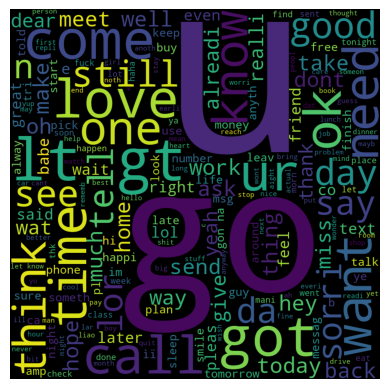

In [42]:
ham_text=" ".join(df[df['target']==0]['transformed_text'])

wc = WordCloud(width=800, height=800).generate(ham_text)

plt.imshow(wc)
plt.axis('off')
plt.show()

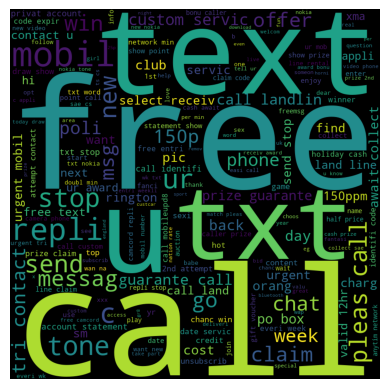

In [43]:
spam_text=" ".join(df[df['target']==1]['transformed_text'])

wc = WordCloud(width=800, height=800).generate(spam_text)

plt.imshow(wc)
plt.axis('off')
plt.show()

In [44]:
from collections import Counter

In [45]:
Word_0=df[df['target']==0]['transformed_text'].apply(lambda x: x.split())
new_0=Counter(Word_0.sum())

In [46]:
pd.DataFrame(Counter(new_0).most_common(30))

,0,1
0,u,883
1,go,404
2,get,349
3,gt,288
4,lt,287
5,2,284
6,come,275
7,got,236
8,know,236
9,like,234


<function matplotlib.pyplot.show(close=None, block=None)>

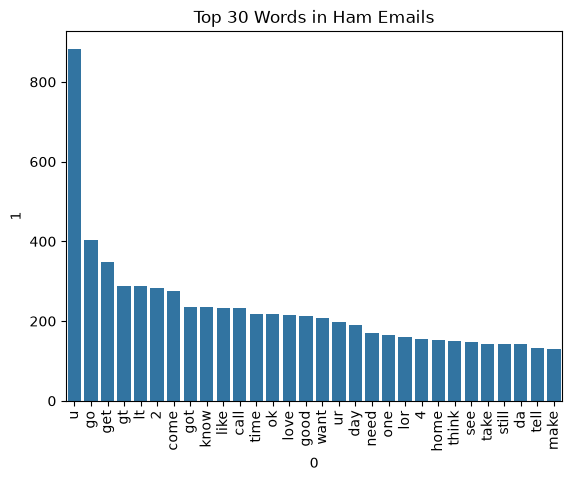

In [47]:
sns.barplot(pd.DataFrame(Counter(new_0).most_common(30)), x=0, y=1)
plt.title('Top 30 Words in Ham Emails')
plt.xticks(rotation=90)
plt.show

In [48]:
Word_1=df[df['target']==1]['transformed_text'].apply(lambda x: x.split())
new_1=Counter(Word_1.sum())

pd.DataFrame(Counter(new_1).most_common(30))


#OR

#from collections import Counter

# 1. Select and combine all spam messages
#spam_text = " ".join(
    #df[df['target'] == 1]['transformed_text'])

# 2. Split the combined text into words
#words = spam_text.split()

# 3. Count each word
#word_counts = Counter(words)

# 4. Display the 10 most frequent words
#print(word_counts.most_common(10))

,0,1
0,call,320
1,free,191
2,2,155
3,txt,141
4,text,122
5,u,119
6,ur,119
7,mobil,114
8,stop,104
9,repli,103


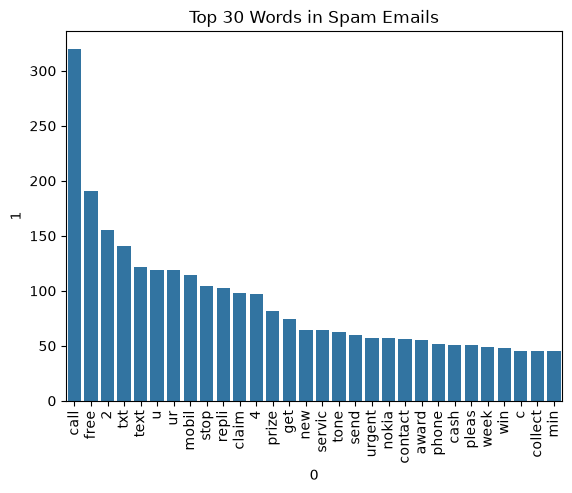

In [49]:
sns.barplot(pd.DataFrame(Counter(new_1).most_common(30)), x=0, y=1)
plt.title('Top 30 Words in Spam Emails')
plt.xticks(rotation=90)
plt.show()

In [50]:
len(new_0), len(new_1)

(5390, 2222)

In [51]:
X=df['transformed_text']
y=df['target']

In [52]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2, stratify=y)

In [53]:
from sklearn.feature_extraction.text import CountVectorizer

cv=CountVectorizer()

X_train_cv=cv.fit_transform(X_train)
X_test_cv=cv.transform(X_test)

In [54]:
from sklearn.naive_bayes import GaussianNB,MultinomialNB,BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score,confusion_matrix,precision_score

In [55]:
clfs={'gnb': GaussianNB(),
      'mnb': MultinomialNB(),
      'bnb': BernoulliNB(),
      'svc': SVC(kernel='sigmoid', gamma=1.0),
      'knc': KNeighborsClassifier(),
      'mnb': MultinomialNB(),
      'dtc': DecisionTreeClassifier(max_depth=5),
      'lrc': LogisticRegression(solver='liblinear', penalty='l1'),
      'rfc': RandomForestClassifier(n_estimators=50, random_state=2),
      'abc': AdaBoostClassifier(n_estimators=50, random_state=2),
      'bc': BaggingClassifier(n_estimators=50, random_state=2),
      'etc': ExtraTreesClassifier(n_estimators=50, random_state=2),
      'gbdt': GradientBoostingClassifier(n_estimators=50,random_state=2),
      'xgb': XGBClassifier(n_estimators=50,random_state=2)}

In [57]:
results = []

for name, clf in clfs.items():
    clf.fit(X_train_cv.toarray(), y_train)
    y_pred=clf.predict(X_test_cv.toarray())
   
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    results.append({'Algorithm' : name,
                    'Accuracy' : accuracy,
                    'Precision': precision,
                    'TN': cm[0][0],
                    'FP': cm[0][1],
                    'FN': cm[1][0],
                    'TP': cm[1][1]})

results_df = pd.DataFrame(results)
display(results_df)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,Algorithm,Accuracy,Precision,TN,FP,FN,TP
0,gnb,0.879110,0.512821,789,114,11,120
1,mnb,0.980658,0.905109,890,13,7,124
2,bnb,0.972921,1.000000,903,0,28,103
3,svc,0.921663,0.673611,856,47,34,97
4,knc,0.911025,0.975610,902,1,91,40
5,dtc,0.930368,0.983607,902,1,71,60
6,lrc,0.978723,0.943089,896,7,15,116
7,rfc,0.975822,0.990741,902,1,24,107
8,abc,0.925532,0.909091,897,6,71,60
9,bc,0.977756,0.990909,902,1,22,109


In [58]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf=TfidfVectorizer()

X_train_tfidf=tfidf.fit_transform(X_train)
X_test_tfidf=tfidf.transform(X_test)

In [59]:
results_1 = []

for name, clf in clfs.items():
    clf.fit(X_train_tfidf.toarray(), y_train)
    y_pred=clf.predict(X_test_tfidf.toarray())
   
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)

    results_1.append({'Algorithm' : name,
                    'Accuracy' : accuracy,
                    'Precision': precision,
                    'TN': cm[0][0],
                    'FP': cm[0][1],
                    'FN': cm[1][0],
                    'TP': cm[1][1]})

results_df = pd.DataFrame(results_1)
display(results_df)

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,Algorithm,Accuracy,Precision,TN,FP,FN,TP
0,gnb,0.876209,0.506494,789,114,14,117
1,mnb,0.968085,1.000000,903,0,33,98
2,bnb,0.972921,1.000000,903,0,28,103
3,svc,0.986460,0.968000,899,4,10,121
4,knc,0.910058,1.000000,903,0,93,38
5,dtc,0.926499,0.823529,888,15,61,70
6,lrc,0.965184,0.935780,896,7,29,102
7,rfc,0.982592,1.000000,903,0,18,113
8,abc,0.918762,0.783133,885,18,66,65
9,bc,0.968085,0.915254,893,10,23,108


In [69]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.naive_bayes import BernoulliNB

bnb = BernoulliNB()


In [70]:
bnb.fit(X_train_tfidf, y_train)
y_pred = bnb.predict(X_test_tfidf)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.9729206963249516
Precision: 1.0
Recall: 0.7862595419847328
F1-score: 0.8803418803418803

Confusion Matrix:
[[903   0]
 [ 28 103]]

Classification Report:
              precision    recall  f1-score   support

           0       0.97      1.00      0.98       903
           1       1.00      0.79      0.88       131

    accuracy                           0.97      1034
   macro avg       0.98      0.89      0.93      1034
weighted avg       0.97      0.97      0.97      1034



In [71]:
def predict_message(message):
    transformed_message = transform_text(message)

    vector_input = tfidf.transform([transformed_message])

    prediction = bnb.predict(vector_input)[0]

    if prediction == 1:
        return "Spam"
    else:
        return "Not Spam (Ham)"

In [72]:
predict_message("Congratulations! You have won a free prize. Claim now!")

'Spam'

In [73]:
import pickle

with open('spam_classifier.pkl', 'wb') as file:
    pickle.dump(bnb, file)

with open('tfidf_vectorizer.pkl', 'wb') as file:
    pickle.dump(tfidf, file)